In [1]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine

DB_PATH = "../data/online_retail.db"
engine = create_engine(f"sqlite:///{DB_PATH}")
print("Setup complete.")

Setup complete.


In [2]:
transactions = pd.read_sql("""
    SELECT CustomerID, Invoice, InvoiceDate
     FROM clean_transactions
      WHERE CustomerID IS NOT NULL
""", engine)

print(f"Loaded {len(transactions):,} transaction line items")
transactions.head()

Loaded 824,279 transaction line items


,CustomerID,Invoice,InvoiceDate
0,13085.0,489434,2009-12-01 07:45:00.000000
1,13085.0,489434,2009-12-01 07:45:00.000000
2,13085.0,489434,2009-12-01 07:45:00.000000
3,13085.0,489434,2009-12-01 07:45:00.000000
4,13085.0,489434,2009-12-01 07:45:00.000000


In [3]:
transactions['InvoiceDate'] = pd.to_datetime(transactions['InvoiceDate'])

transactions['InvoiceMonth'] = transactions['InvoiceDate'].dt.to_period('M')

transactions['CohortMonth'] = transactions.groupby('CustomerID')['InvoiceMonth'].transform('min')

transactions[['CustomerID', 'InvoiceDate', 'InvoiceMonth', 'CohortMonth']].head()

,CustomerID,InvoiceDate,InvoiceMonth,CohortMonth
0,13085.0,2009-12-01 07:45:00,2009-12,2009-12
1,13085.0,2009-12-01 07:45:00,2009-12,2009-12
2,13085.0,2009-12-01 07:45:00,2009-12,2009-12
3,13085.0,2009-12-01 07:45:00,2009-12,2009-12
4,13085.0,2009-12-01 07:45:00,2009-12,2009-12


In [4]:
def get_month_diff(row):
    return (row['InvoiceMonth'].year - row['CohortMonth'].year) * 12 + (row['InvoiceMonth'].month - row['CohortMonth'].month)
transactions['CohortIndex'] = transactions.apply(get_month_diff, axis=1)

transactions[['CustomerID', 'CohortMonth', 'InvoiceMonth', 'CohortIndex']].head()

,CustomerID,CohortMonth,InvoiceMonth,CohortIndex
0,13085.0,2009-12,2009-12,0
1,13085.0,2009-12,2009-12,0
2,13085.0,2009-12,2009-12,0
3,13085.0,2009-12,2009-12,0
4,13085.0,2009-12,2009-12,0


In [5]:

cohort_data = transactions.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].nunique().reset_index()

cohort_pivot = cohort_data.pivot(index='CohortMonth', columns='CohortIndex', values='CustomerID')

cohort_pivot

CohortIndex,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,1044.0,391.0,358.0,446.0,410.0,408.0,407.0,374.0,355.0,392.0,...,319.0,273.0,316.0,303.0,287.0,274.0,332.0,319.0,427.0,218.0
2010-01,395.0,86.0,120.0,120.0,110.0,116.0,105.0,91.0,114.0,135.0,...,60.0,86.0,74.0,69.0,73.0,93.0,73.0,88.0,29.0,NaN
2010-02,361.0,109.0,82.0,110.0,93.0,76.0,79.0,103.0,99.0,106.0,...,74.0,67.0,61.0,53.0,85.0,90.0,62.0,23.0,NaN,NaN
2010-03,436.0,95.0,113.0,103.0,100.0,87.0,105.0,130.0,126.0,50.0,...,74.0,76.0,69.0,74.0,89.0,93.0,33.0,NaN,NaN,NaN
2010-04,291.0,67.0,58.0,47.0,54.0,67.0,79.0,76.0,33.0,34.0,...,43.0,41.0,41.0,50.0,61.0,19.0,NaN,NaN,NaN,NaN
2010-05,254.0,49.0,45.0,49.0,48.0,66.0,56.0,33.0,17.0,22.0,...,33.0,36.0,42.0,40.0,12.0,NaN,NaN,NaN,NaN,NaN
2010-06,269.0,58.0,53.0,55.0,62.0,76.0,35.0,25.0,22.0,32.0,...,33.0,37.0,55.0,16.0,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,183.0,38.0,37.0,52.0,55.0,28.0,21.0,28.0,26.0,22.0,...,32.0,45.0,17.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,158.0,39.0,50.0,51.0,29.0,21.0,16.0,22.0,23.0,21.0,...,32.0,11.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
cohort_sizes = cohort_pivot.iloc[:,0]
retention_table = cohort_pivot.divide(cohort_sizes, axis =0) * 100
retention_table.round(1)

CohortIndex,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,100.0,37.5,34.3,42.7,39.3,39.1,39.0,35.8,34.0,37.5,...,30.6,26.1,30.3,29.0,27.5,26.2,31.8,30.6,40.9,20.9
2010-01,100.0,21.8,30.4,30.4,27.8,29.4,26.6,23.0,28.9,34.2,...,15.2,21.8,18.7,17.5,18.5,23.5,18.5,22.3,7.3,NaN
2010-02,100.0,30.2,22.7,30.5,25.8,21.1,21.9,28.5,27.4,29.4,...,20.5,18.6,16.9,14.7,23.5,24.9,17.2,6.4,NaN,NaN
2010-03,100.0,21.8,25.9,23.6,22.9,20.0,24.1,29.8,28.9,11.5,...,17.0,17.4,15.8,17.0,20.4,21.3,7.6,NaN,NaN,NaN
2010-04,100.0,23.0,19.9,16.2,18.6,23.0,27.1,26.1,11.3,11.7,...,14.8,14.1,14.1,17.2,21.0,6.5,NaN,NaN,NaN,NaN
2010-05,100.0,19.3,17.7,19.3,18.9,26.0,22.0,13.0,6.7,8.7,...,13.0,14.2,16.5,15.7,4.7,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,21.6,19.7,20.4,23.0,28.3,13.0,9.3,8.2,11.9,...,12.3,13.8,20.4,5.9,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,20.8,20.2,28.4,30.1,15.3,11.5,15.3,14.2,12.0,...,17.5,24.6,9.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,24.7,31.6,32.3,18.4,13.3,10.1,13.9,14.6,13.3,...,20.3,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
retention_table.to_csv("../output/cohort_retention.csv")
print("Saved to output folder.")

Saved to output folder.


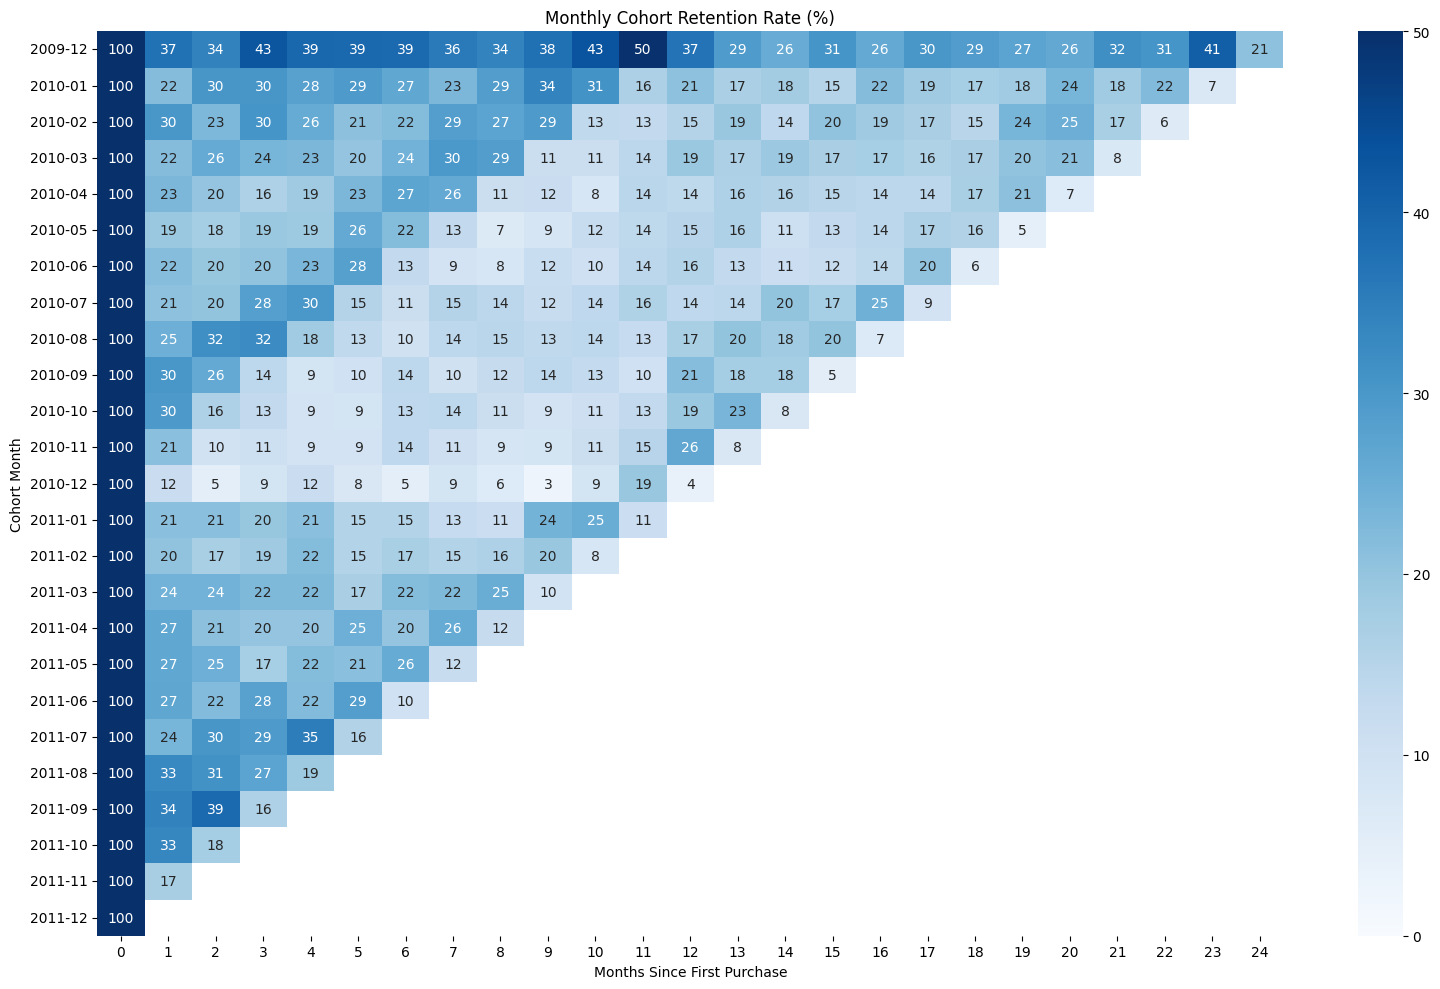

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (16,10))
sns.heatmap(retention_table, annot = True, fmt='.0f', cmap ='Blues', vmin = 0, vmax = 50)
plt.title('Monthly Cohort Retention Rate (%)')
plt.xlabel('Months Since First Purchase')
plt.ylabel('Cohort Month')
plt.tight_layout()
plt.savefig('../output/cohort_heatmap.png', dpi =150)
plt.show()

In [9]:
avg_month1_retention = retention_table[1].mean()
print(f"Average Month-1 Retention Rate: {avg_month1_retention:.1f}%")

Average Month-1 Retention Rate: 25.0%


In [10]:
rfm = pd.read_sql("SELECT * FROM rfm_segments", engine)
print(f"Loaded {len(rfm):,} customers")

Loaded 5,939 customers


In [11]:
repeat_customers = (rfm['Frequency'] > 1).sum()
total_customers = len(rfm)
repeat_rate = (repeat_customers / total_customers) * 100

print(f"Repeat Purchase Rate: {repeat_rate:.1f}% ({repeat_customers:,} of {total_customers:,} customers)")

Repeat Purchase Rate: 75.5% (4,481 of 5,939 customers)


In [12]:
kpi_query = """
SELECT 
    SUM(LineTotal) AS total_revenue,
    COUNT(DISTINCT Invoice) AS total_orders,
    COUNT(DISTINCT CustomerID) AS total_customers,
    SUM(LineTotal) / COUNT(DISTINCT Invoice) AS avg_order_value
FROM clean_transactions
"""

kpis = pd.read_sql(kpi_query, engine)
kpis

,total_revenue,total_orders,total_customers,avg_order_value
0,1.943466e+07,48354,5939,401.92458


In [13]:
rfm.to_csv("../output/rfm_customers.csv", index = False)

retention_table.to_csv("../output/cohort_retention.csv")

monthly_revenue = pd.read_sql("""
    SELECT
        strftime('%Y-%m', InvoiceDate) AS Month,
        SUM(LineTotal) AS Revenue,
        COUNT(DISTINCT Invoice) AS Orders
    FROM clean_transactions
    GROUP BY MONTH
    ORDER BY MONTH
""", engine)

monthly_revenue.to_csv("../output/monthly_revenue.csv", index = False)

print("All files exported to /output")

All files exported to /output


In [14]:
print(clean_transactions_revenue := pd.read_sql("SELECT SUM(LineTotal) as total FROM clean_transactions", engine))

          total
0  1.943466e+07


In [15]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine

DB_PATH = "../data/online_retail.db"
engine = create_engine(f"sqlite:///{DB_PATH}")
print("Setup complete.")

Setup complete.


In [16]:
transaction_detail = pd.read_sql("""
    SELECT 
        Invoice,
        InvoiceDate,
        CustomerID,
        Quantity,
        Price,
        Country
    FROM clean_transactions
""", engine)

print(f"Loaded {len(transaction_detail):,} rows")
transaction_detail.to_csv("../output/transaction_detail.csv", index=False)
print("Saved to output folder.")

Loaded 1,061,149 rows
Saved to output folder.
